<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_Learning-Langchain-AI-Agent/blob/main/CH4_Using_LangGraph_as_workflow_add_messages.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title **1. add_message(LangGraph에서 대화 기록(메시지 상태)을 업데이트하기 위해 사용하는 리듀서(Reducer) 함수)**
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage

In [2]:
add_messages

<function langgraph.graph.message._add_messages_wrapper.<locals>._add_messages(left: 'Messages | None' = None, right: 'Messages | None' = None, **kwargs: 'Any') -> 'Messages | Callable[[Messages, Messages], Messages]'>

In [3]:
state = {
    "messages": [
        HumanMessage(content="파이썬이란?")
    ]
}

In [4]:
new_message = AIMessage(
    content="파이썬은 프로그래밍 언어입니다."
)

In [5]:
state["messages"] = add_messages(
    state["messages"],
    [new_message]
)

In [6]:
state

{'messages': [HumanMessage(content='파이썬이란?', additional_kwargs={}, response_metadata={}, id='72c68801-0bd4-450d-a608-2718a0db271e'),
  AIMessage(content='파이썬은 프로그래밍 언어입니다.', additional_kwargs={}, response_metadata={}, id='9e716497-b55d-4fa5-9ad8-1f150456f918', tool_calls=[], invalid_tool_calls=[])]}

In [7]:
state["messages"]

[HumanMessage(content='파이썬이란?', additional_kwargs={}, response_metadata={}, id='72c68801-0bd4-450d-a608-2718a0db271e'),
 AIMessage(content='파이썬은 프로그래밍 언어입니다.', additional_kwargs={}, response_metadata={}, id='9e716497-b55d-4fa5-9ad8-1f150456f918', tool_calls=[], invalid_tool_calls=[])]

In [8]:
for message in state["messages"]:
    print(f"{message.type}: {message.content}")

human: 파이썬이란?
ai: 파이썬은 프로그래밍 언어입니다.


**user별로 대화 history를 저장**

In [9]:
# 1. 기존 대화 목록 (ID 지정)
old_msgs = [
    HumanMessage(content="안녕?", id="조상구"),
    AIMessage(content="반가워요!", id="홍길동"),
]

# 2. 새로 들어온 메시지
new_msgs = [
    AIMessage(content="안녕하세요! 무엇을 도와드릴까요?", id="조상구"),  # ID "2"가 겹침 -> 덮어쓰기(수정)
    HumanMessage(content="날씨 알려줘", id="홍길동"),  # 새로운 ID "3" -> 뒤에 추가
]

# 3. add_messages 실행 (두 리스트를 똑똑하게 병합)
result = add_messages(old_msgs, new_msgs)
result

[AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={}, response_metadata={}, id='조상구', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='날씨 알려줘', additional_kwargs={}, response_metadata={}, id='홍길동')]

**클래스를 정의하 방법**

In [10]:
# @title **2. add_message를 Class로 정의하고 Langraph Workflow 실행**
from typing import Annotated, TypedDict

In [11]:
# 1. 그래프의 상태(State) 및 리듀서 정의
class State(TypedDict):
    # add_messages 리듀서가 적용된 부분입니다.
    messages: Annotated[list, add_messages]

In [12]:
state: State = {
    "messages": [
        HumanMessage(content="파이썬이란?")
    ]
}

state

{'messages': [HumanMessage(content='파이썬이란?', additional_kwargs={}, response_metadata={})]}

In [13]:
from langgraph.graph import StateGraph

In [14]:
workflow = StateGraph(State)
graph = StateGraph(State)
graph

In [15]:
# 노드와 에지가 설정되기 전에 컴파일을 수행하면 에러가 발생
# graph = workflow.compile()

In [16]:
from langgraph.graph import StateGraph, START, END

In [17]:
def chatbot_node(state):
  # 여기에 챗봇 로직 작성
  return {"messages": [("assistant", "안녕하세요!")]}

In [18]:
# 5. 노드 및 에지(흐름) 연결
workflow.add_node("chatbot", chatbot_node)
workflow.add_edge(START, "chatbot")
workflow.add_edge("chatbot", END)

In [19]:
graph

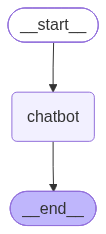

In [20]:
# 6. 그래프 컴파일 (실행 가능한 형태의 앱으로 변환)
graph = workflow.compile()
graph

In [21]:
# @title **3. add_message, user 이름, 나이, 대화 건 수 등을 Class로 정의하고 Langraph Workflow 실행**
# 1. State 정의
class State(TypedDict):
    user_name: str
    age: int
    is_active: bool
    chat_count: int

In [22]:
# @title **LangGraph MemorySaver: 사용자별 대화 상태 저장하기**
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

# ─────────────────────────────────────────────
# 1. State: 그래프가 기억할 "데이터 상자"
# ─────────────────────────────────────────────
class State(TypedDict):
    user_name: str     # 사용자 이름
    age: int           # 나이
    is_active: bool    # 활동 여부
    chat_count: int    # 대화 횟수

# ─────────────────────────────────────────────
# 2. Node: 상태를 읽고, 변경할 값만 반환하는 "작업 단계"
# ─────────────────────────────────────────────
def process_node(state: State):
    # 저장된 값이 없을 때를 대비해 .get()으로 기본값 지정
    count = state.get("chat_count", 0)
    return {"chat_count": count + 1}   # 바꾸고 싶은 값만 돌려주면 됨

# ─────────────────────────────────────────────
# 3. Graph: START → process → END
# ─────────────────────────────────────────────
builder = StateGraph(State)
builder.add_node("process", process_node)
builder.add_edge(START, "process")
builder.add_edge("process", END)

# ─────────────────────────────────────────────
# 4. MemorySaver: 상태를 저장하는 "메모장"
#    thread_id = 대화방 번호 (방마다 따로 저장됨)
# ─────────────────────────────────────────────
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

config_A = {"configurable": {"thread_id": "user_A"}}   # A의 대화방
config_B = {"configurable": {"thread_id": "user_B"}}   # B의 대화방

# 대화를 한 번 실행하고 결과를 보기 좋게 출력하는 도우미 함수
def chat(label, input_data, config):
    result = graph.invoke(input_data, config=config)
    print(f"[{label}] chat_count = {result['chat_count']}  |  전체 상태: {result}")

# ─────────────────────────────────────────────
# 5. 실행
# ─────────────────────────────────────────────
print("=== 첫 대화: 사용자 정보를 처음 입력 ===")
chat("User A, 1번째", {"user_name": "Kim", "age": 25, "is_active": True,  "chat_count": 0}, config_A)
chat("User B, 1번째", {"user_name": "Lee", "age": 30, "is_active": False, "chat_count": 0}, config_B)

print("\n=== 다시 대화: 새로 입력한 건 거의 없는데 이름·나이는 기억될까? ===")
chat("User A, 2번째", {}, config_A)   # 빈 입력 → 저장된 상태를 이어받음
chat("User A, 3번째", {}, config_A)

# ─────────────────────────────────────────────
# 6. 최종 저장 상태 확인
# ─────────────────────────────────────────────
print("\n=== 최종 저장 상태 ===")
print("User A:", graph.get_state(config_A).values)   # chat_count = 3
print("User B:", graph.get_state(config_B).values)   # chat_count = 1

=== 첫 대화: 사용자 정보를 처음 입력 ===
[User A, 1번째] chat_count = 1  |  전체 상태: {'user_name': 'Kim', 'age': 25, 'is_active': True, 'chat_count': 1}
[User B, 1번째] chat_count = 1  |  전체 상태: {'user_name': 'Lee', 'age': 30, 'is_active': False, 'chat_count': 1}

=== 다시 대화: 새로 입력한 건 거의 없는데 이름·나이는 기억될까? ===
[User A, 2번째] chat_count = 2  |  전체 상태: {'user_name': 'Kim', 'age': 25, 'is_active': True, 'chat_count': 2}
[User A, 3번째] chat_count = 3  |  전체 상태: {'user_name': 'Kim', 'age': 25, 'is_active': True, 'chat_count': 3}

=== 최종 저장 상태 ===
User A: {'user_name': 'Kim', 'age': 25, 'is_active': True, 'chat_count': 3}
User B: {'user_name': 'Lee', 'age': 30, 'is_active': False, 'chat_count': 1}


- **MessagesState**

> add_messages가 이미 세팅되어 있는 미리 만들어진 상태(State) 클래스

> 매번 TypedDict와 Annotated를 써서 messages 필드를 직접 정의하는 번거로움을 없애주기 위해 LangGraph에서 기본으로 제공하는 단축키(Shortcut) 같은 클래스

> class MessagesState(TypedDict):
>>  messages: Annotated[list[AnyMessage], add_messages]

In [23]:
# @title **4. Conitive를 위한 Tool 사용의 자율성 부여**
from langchain_core.tools import tool
from langchain_core.messages import AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode

# 1. 사용자 정의 도구
@tool
def add(a: int, b: int) -> int:
    """두 숫자를 더한다."""
    return a + b

# 2. LLM이 해 줄 "도구 호출 요청"을 직접 만들기
ai_msg = AIMessage(
    content="",
    tool_calls=[{"name": "add", "args": {"a": 123, "b": 456}, "id": "call_1"}],
)

# 3. 그래프: START → tools → END
builder = StateGraph(MessagesState)
builder.add_node("tools", ToolNode([add]))
builder.add_edge(START, "tools")
builder.add_edge("tools", END)
graph = builder.compile()

# 4. 실행 & 출력
result = graph.invoke({"messages": [ai_msg]})
for m in result["messages"]:
    print(type(m).__name__, "→", m.content, getattr(m, "tool_calls", ""))

AIMessage →  [{'name': 'add', 'args': {'a': 123, 'b': 456}, 'id': 'call_1', 'type': 'tool_call'}]
ToolMessage → 579 


In [24]:
ai_msg

AIMessage(content='', additional_kwargs={}, response_metadata={}, id='d7b7c71d-6151-4128-a75d-de71e1457ed1', tool_calls=[{'name': 'add', 'args': {'a': 123, 'b': 456}, 'id': 'call_1', 'type': 'tool_call'}], invalid_tool_calls=[])

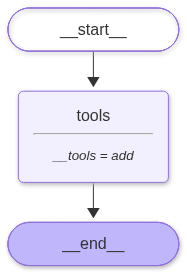

In [25]:
graph

In [ ]:
!pip install -q -U langchain-core langchain langchain-google-genai langgraph

# 설치한 버전이 적용되도록 런타임을 자동 재시작 (세션 끊김 메시지가 떠도 정상)
import os
os.kill(os.getpid(), 9)

In [1]:
from langchain_core.tools import tool
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display

# LLM call
import os
from google.colab import userdata
YOUR_API_KEY = userdata.get('Gemini-API-Key')
os.environ["GOOGLE_API_KEY"] = YOUR_API_KEY

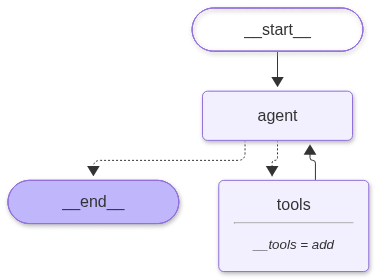

HumanMessage → 123 더하기 456은? 
AIMessage → [] [{'name': 'add', 'args': {'a': 123, 'b': 456}, 'id': 'call_4848595734973589155', 'type': 'tool_call'}]
ToolMessage → 579 
AIMessage → [{'type': 'text', 'text': '123 더하기 456은 **579**입니다.', 'extras': {'signature': 'ErMBCrABAWkUfRM++/XsJJZbymD7uNJX+RhFCwwbRSDKRDeh3D6/EHWN/t+IV2gnd6SJlo2gn6pFB1NnZ+P09Z9gjaZriyPEwPbfyrLkT4js60nXcv8OGkZpNj0fE93WnpQpgShG752ZyCBA40Ts996UlsFSFMa+UmxzqBnrnyqc72uUD9h7qn7dDxFX3rMn6MQvl4x+EwiYcXm1BXREiPcJjbNXzoP4FBQcaT+DtPuumaFepds='}}] []


In [2]:
# 1. 사용자 정의 도구: 함수 위에 @tool만 붙이면 끝 (docstring이 LLM에게 주는 설명서)
@tool
def add(a: int, b: int) -> int:
    """두 숫자를 더한다."""
    return a + b

# 2. LangChain 체인: 프롬프트 | LLM(도구 연결)
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash")
prompt = ChatPromptTemplate.from_messages([
    ("system", "당신은 계산 도우미입니다. 계산은 반드시 도구를 사용하세요."),
    ("placeholder", "{messages}"),
])
chain = prompt | llm.bind_tools([add])

# 3. 노드: 체인을 그래프의 한 단계로 감싸기
# 체인은 "입력을 넣으면 답이 나오는 기계"이고, 그래프의 노드는 "상태(state)를 받아서 상태에 추가할 값을 돌려주는 함수"
# 입력과 출력의 모양이 서로 다르기 때문에 체인을 그대로 add_node에 넣을 수 없고, 모양을 맞춰 주는 어댑터 함수 --> agent_node
def agent_node(state: MessagesState):
    return {"messages": [chain.invoke({"messages": state["messages"]})]}

# 4. 그래프 구성
builder = StateGraph(MessagesState)
builder.add_node("agent", agent_node)          # 체인 실행 (LLM 판단)
builder.add_node("tools", ToolNode([add]))     # 도구 실행
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition)  # tool_calls 있으면 tools, 없으면 END
builder.add_edge("tools", "agent")             # 도구 결과를 들고 다시 agent로
graph = builder.compile()

# 5. 그래프 그리기
display(Image(graph.get_graph().draw_mermaid_png()))

# 6. 실행 & 메시지 흐름 확인
result = graph.invoke({"messages": [("user", "123 더하기 456은?")]})
for m in result["messages"]:
    print(type(m).__name__, "→", m.content, getattr(m, "tool_calls", ""))

### END